Executing on Device: cuda
Training Baseline...
Epoch 1/10 | Train Loss: 3.6909 | Val Acc: 21.81%
Epoch 2/10 | Train Loss: 2.8286 | Val Acc: 33.11%
Epoch 3/10 | Train Loss: 2.2862 | Val Acc: 40.49%
Epoch 4/10 | Train Loss: 1.9151 | Val Acc: 46.17%
Epoch 5/10 | Train Loss: 1.6411 | Val Acc: 51.96%
Epoch 6/10 | Train Loss: 1.4195 | Val Acc: 56.57%
Epoch 7/10 | Train Loss: 1.2255 | Val Acc: 60.08%
Epoch 8/10 | Train Loss: 1.0681 | Val Acc: 62.97%
Epoch 9/10 | Train Loss: 0.9412 | Val Acc: 64.66%
Epoch 10/10 | Train Loss: 0.8813 | Val Acc: 65.19%
Saving baseline configuration to baseline_cache_ep10_frac1.pt...

Training Modified Model (HD Optimizer: True)...
Epoch 1/10 | Train Loss: 3.5323 | Val Acc: 27.27%
Epoch 2/10 | Train Loss: 2.8042 | Val Acc: 31.23%
Epoch 3/10 | Train Loss: 2.6623 | Val Acc: 33.26%
Epoch 4/10 | Train Loss: 2.5963 | Val Acc: 33.65%
Epoch 5/10 | Train Loss: 2.5495 | Val Acc: 34.89%
Epoch 6/10 | Train Loss: 2.4950 | Val Acc: 35.82%
Epoch 7/10 | Train Loss: 2.4476 | Val 

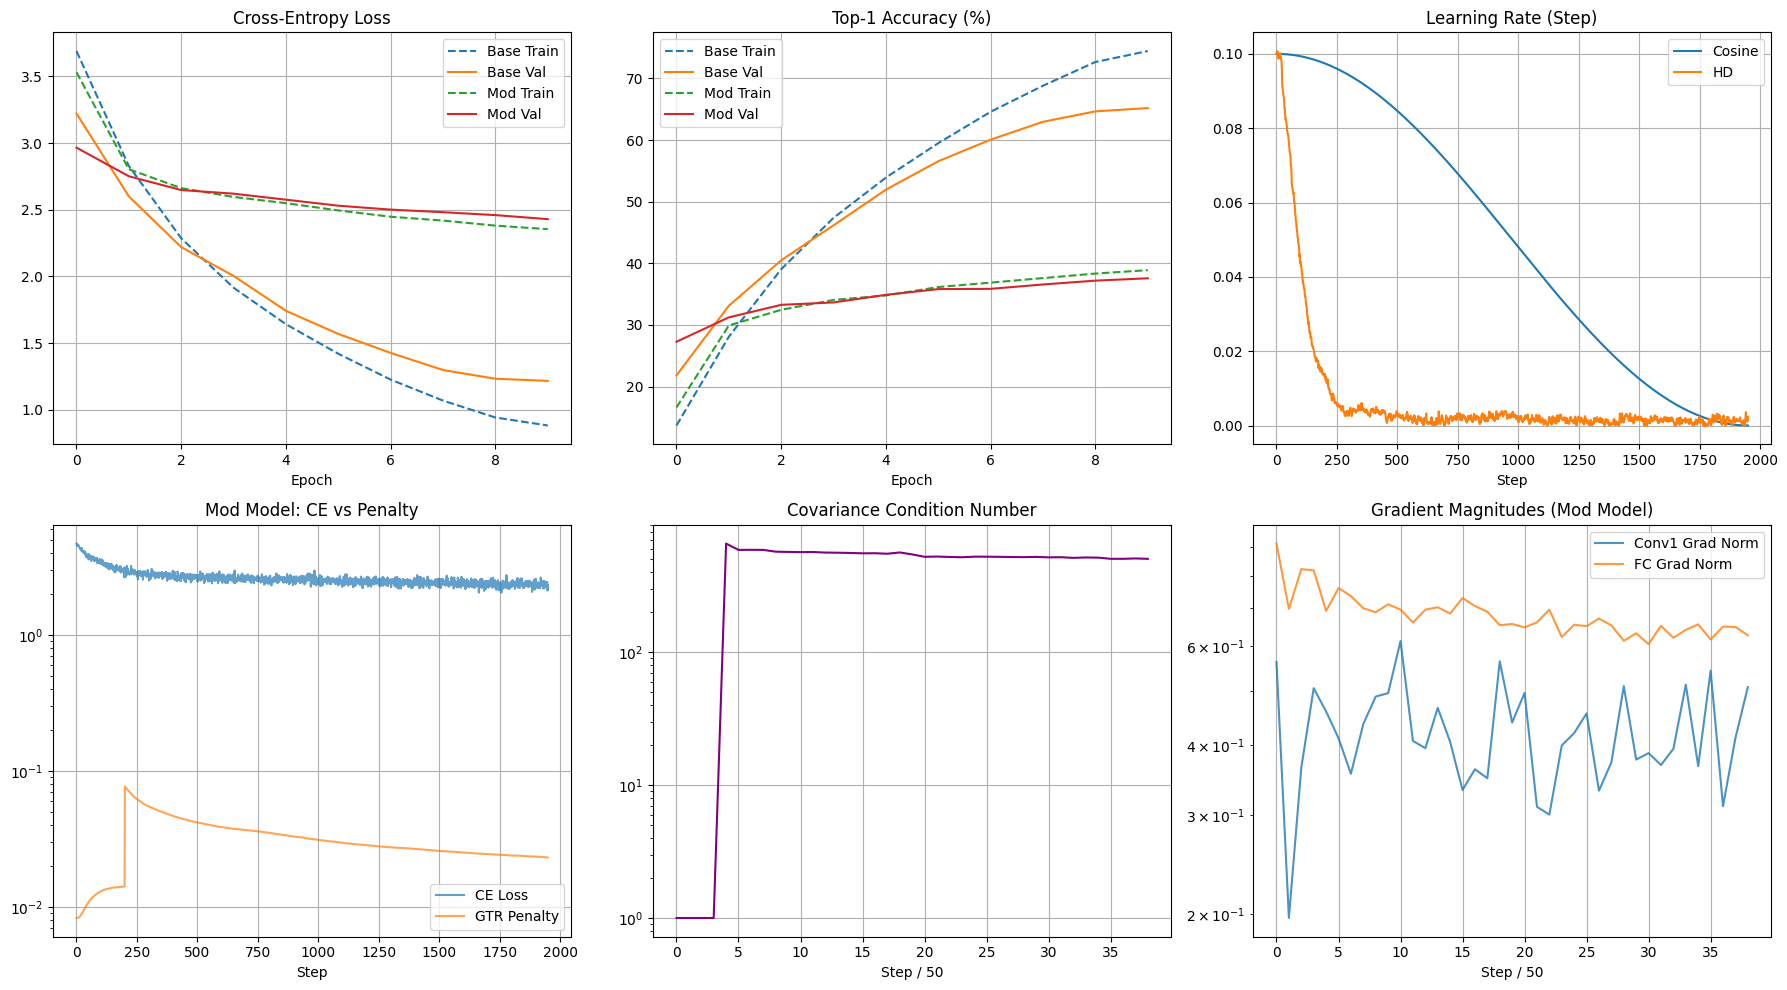

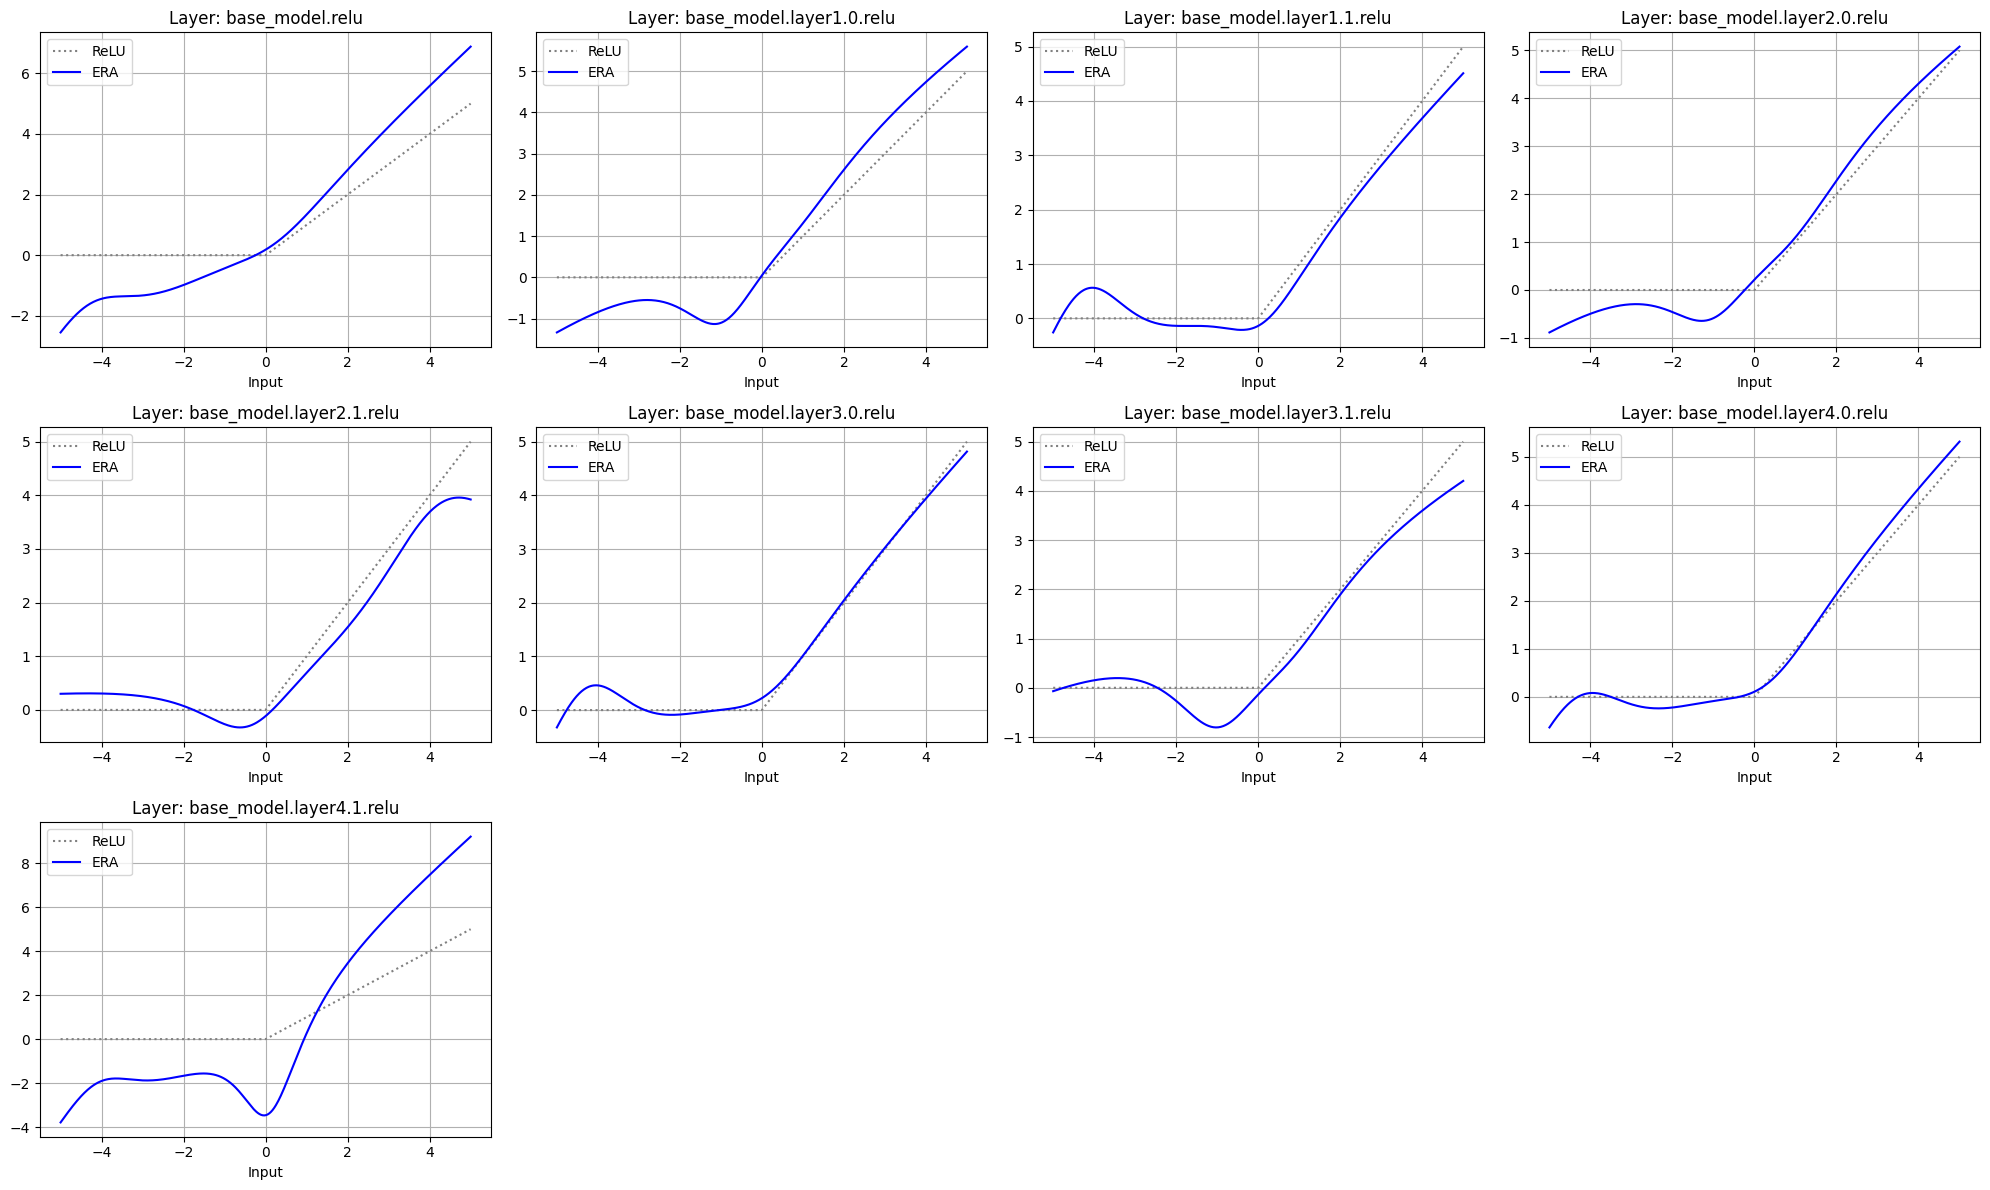

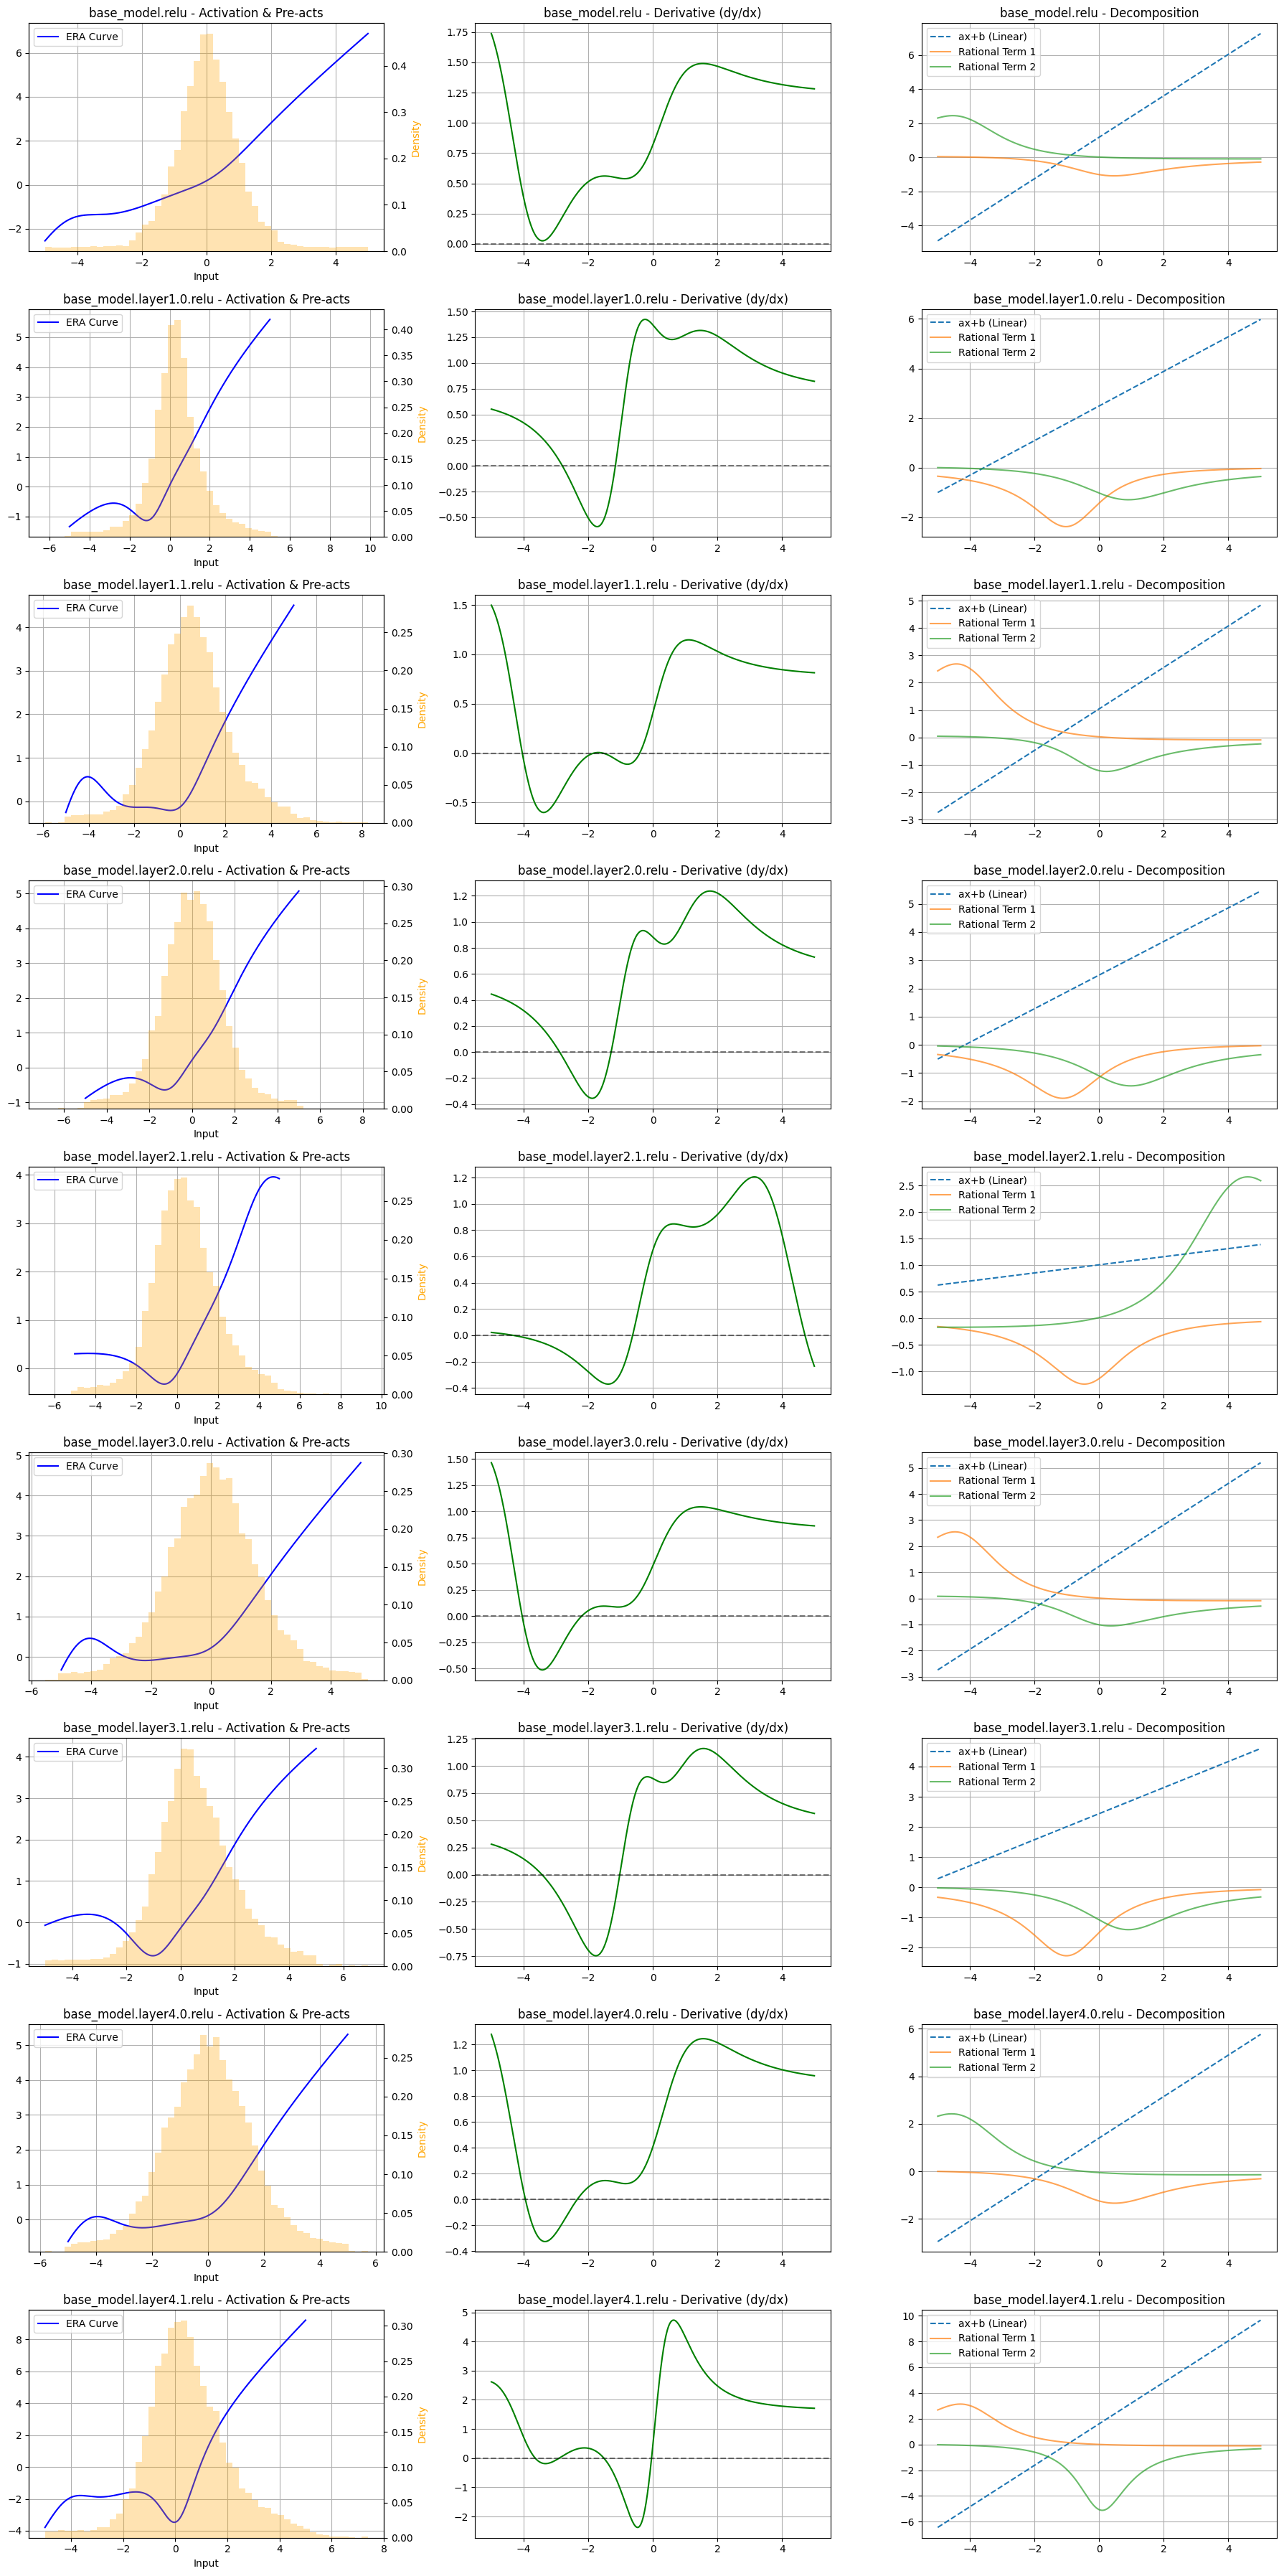

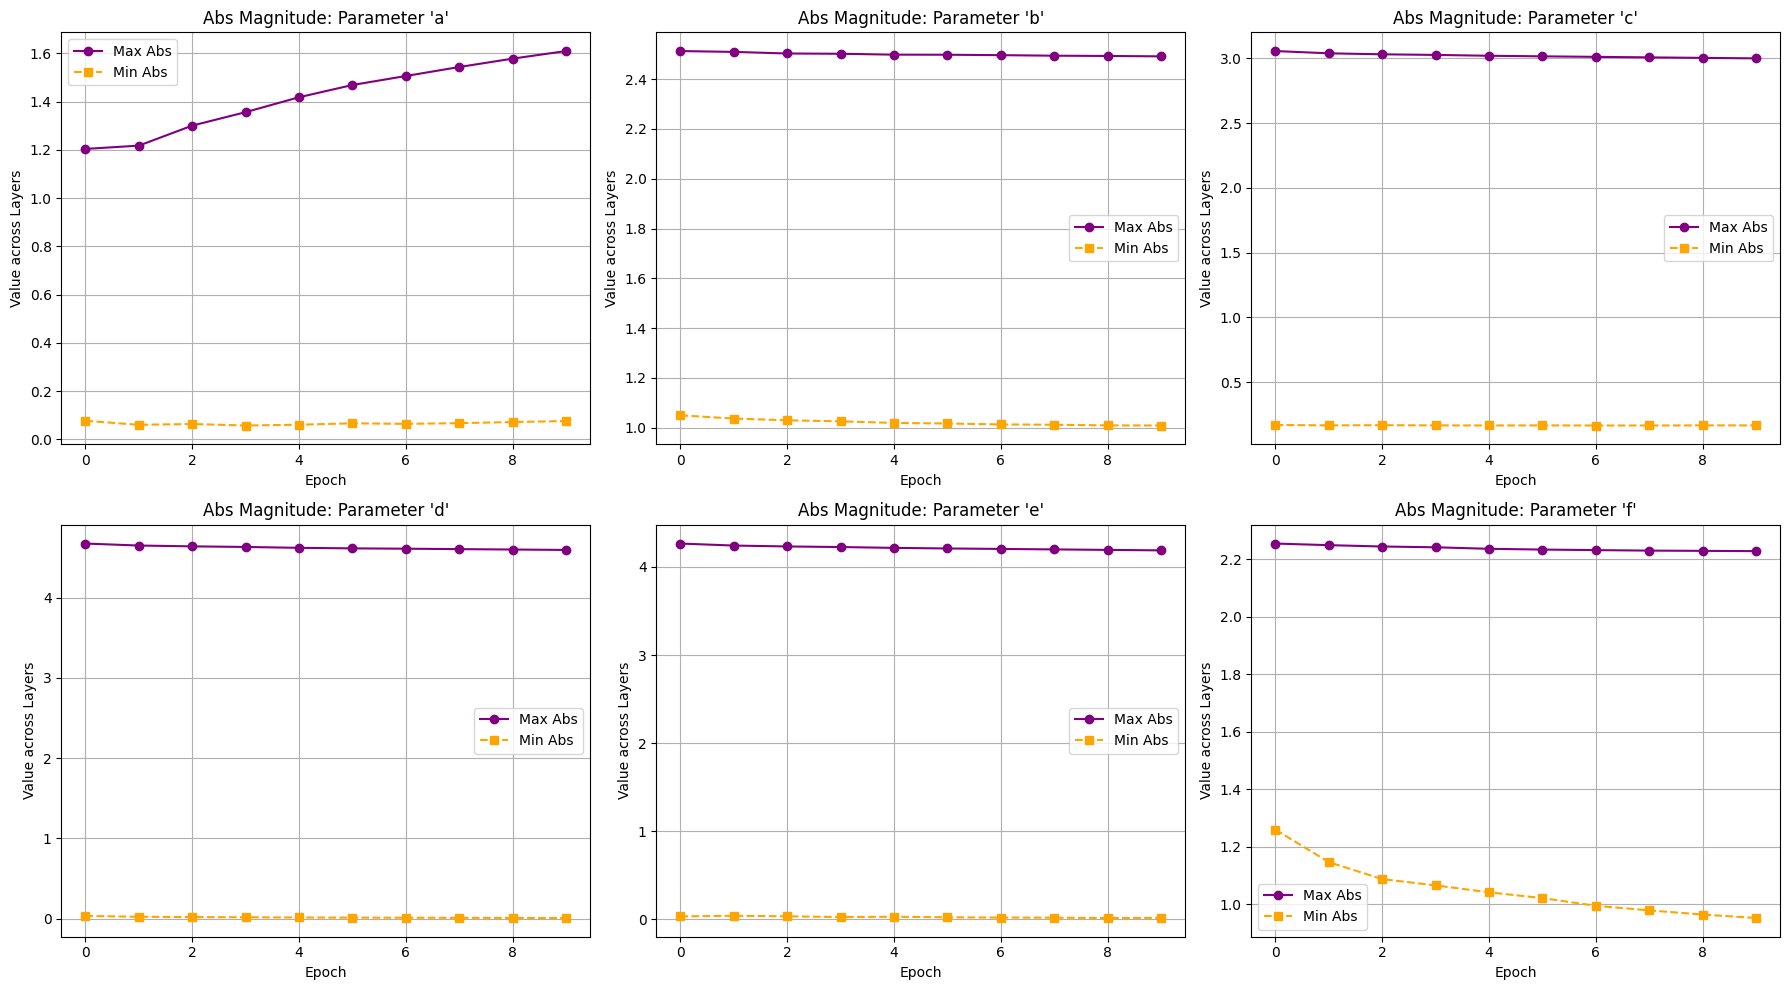

In [14]:
import os
import copy
import math
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18
import matplotlib.pyplot as plt
import numpy as np


# ==========================================
# CONFIGURATION
# ==========================================
DEBUG_MODE = False
USE_HD = True           
DATA_FRACTION = 1
HYPER_LR = 1e-3

# ==========================================
# 1. Layer-wise Enhanced Rational Activation (ERA)
# ==========================================
class LayerERA(nn.Module):
    def __init__(self):
        super().__init__()
        self.a = nn.Parameter(torch.tensor(1.0))
        self.b = nn.Parameter(torch.tensor(0.0))
        self.c = nn.Parameter(torch.randn(2) * 0.1)
        self.d = nn.Parameter(torch.randn(2) * 0.1)
        self.e = nn.Parameter(torch.randn(2))
        self.f = nn.Parameter(torch.ones(2)) 
        
        self.last_input = None 
        self._initialize_to_swish()

    def _initialize_to_swish(self):
        optimizer = optim.Adam(self.parameters(), lr=0.05)
        x = torch.linspace(-5, 5, 1000).view(-1, 1)
        y_target = x * torch.sigmoid(x)
        
        for _ in range(500):
            optimizer.zero_grad()
            y_pred = self.forward(x)
            loss = nn.functional.mse_loss(y_pred, y_target)
            loss.backward()
            optimizer.step()

    def forward(self, x):
        if not self.training:
            if self.last_input is None:
                self.last_input = x.detach().cpu().view(-1)
            else:
                combined = torch.cat([self.last_input, x.detach().cpu().view(-1)])
                indices = torch.randperm(combined.size(0))[:10000]
                self.last_input = combined[indices]

        term1 = (self.c[0] * x + self.d[0]) / ((x - self.e[0])**2 + self.f[0]**2 + 1e-6)
        term2 = (self.c[1] * x + self.d[1]) / ((x - self.e[1])**2 + self.f[1]**2 + 1e-6)
        return self.a * x + self.b + term1 + term2

# ==========================================
# 2. Hypergradient Descent Optimizer
# ==========================================
class SGDHD(optim.SGD):
    def __init__(self, params, lr=0.1, hyper_lr=1e-4, **kwargs): 
        super().__init__(params, lr=lr, **kwargs)
        self.hyper_lr = hyper_lr

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            loss = closure()

        raw_dot_product = 0.0
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if 'prev_update_dir' in state:
                    raw_dot_product += torch.sum(p.grad * state['prev_update_dir']).item()

        for group in self.param_groups:
            new_lr = group['lr'] + self.hyper_lr * raw_dot_product
            group['lr'] = max(1e-6, min(0.5, new_lr))

        prev_params = {}
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is not None:
                    prev_params[p] = p.clone()

        super().step()

        for group in self.param_groups:
            current_lr = group['lr']
            for p in group['params']:
                if p.grad is None:
                    continue
                update_dir = (prev_params[p] - p) / current_lr
                self.state[p]['prev_update_dir'] = update_dir

        return loss

# ==========================================
# 3. Network Architectures
# ==========================================
def replace_relu_with_era(module):
    for name, child in module.named_children():
        if isinstance(child, nn.ReLU):
            setattr(module, name, LayerERA())
        else:
            replace_relu_with_era(child)

def get_all_eras(module, prefix=''):
    eras = {}
    for name, child in module.named_children():
        full_name = f"{prefix}.{name}" if prefix else name
        if isinstance(child, LayerERA):
            eras[full_name] = child
        else:
            eras.update(get_all_eras(child, full_name))
    return eras

class ModifiedResNet18(nn.Module):
    def __init__(self, use_era=False, return_features=False):
        super().__init__()
        self.return_features = return_features
        self.base_model = resnet18(num_classes=100)
        self.base_model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.base_model.maxpool = nn.Identity()
        
        if use_era:
            replace_relu_with_era(self.base_model)

    def forward(self, x):
        x = self.base_model.conv1(x)
        x = self.base_model.bn1(x)
        x = getattr(self.base_model, 'relu', lambda act: act)(x) if not hasattr(self.base_model, 'relu') else self.base_model.relu(x)
        x = self.base_model.maxpool(x)

        x = self.base_model.layer1(x)
        x = self.base_model.layer2(x)
        x = self.base_model.layer3(x)
        x = self.base_model.layer4(x)

        x = self.base_model.avgpool(x)
        Z = torch.flatten(x, 1)
        logits = self.base_model.fc(Z)
        
        if self.return_features:
            return logits, Z
        return logits

# ==========================================
# 4. Training Loop
# ==========================================
def train_model(model, trainloader, valloader, device, use_gtr=False, use_hd=False, epochs=5):
    initial_lr = 0.1
    weight_decay = 5e-4
    momentum = 0.9

    all_eras = get_all_eras(model)

    if use_hd:
        era_num_params = [p for n, p in model.named_parameters() if 'LayerERA' in n and ('.c' in n or '.d' in n)]
        era_den_params = [p for n, p in model.named_parameters() if 'LayerERA' in n and ('.e' in n or '.f' in n)]
        era_base_params = [p for n, p in model.named_parameters() if 'LayerERA' in n and ('.a' in n or '.b' in n)]
        
        fc_params = [model.base_model.fc.weight, model.base_model.fc.bias]
        base_conv_params = [p for n, p in model.named_parameters() if 'fc' not in n and 'LayerERA' not in n]

        optimizer = SGDHD([
            {'params': base_conv_params, 'weight_decay': weight_decay},
            {'params': fc_params, 'weight_decay': 0.0},
            {'params': era_base_params, 'weight_decay': weight_decay},
            {'params': era_num_params, 'weight_decay': 5e-3}, 
            {'params': era_den_params, 'weight_decay': 0.0}   
        ], lr=initial_lr, hyper_lr=HYPER_LR, momentum=momentum, nesterov=True)
        scheduler = None
    else:
        optimizer = optim.SGD(model.parameters(), lr=initial_lr, 
                              momentum=momentum, weight_decay=weight_decay, nesterov=True)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(trainloader))

    criterion = nn.CrossEntropyLoss()
    alpha, epsilon = 0.99, 1e-2 
    sigma_global = None
    warmup_steps, global_step = 200, 0

    metrics = {
        'train_losses': [], 'val_losses': [], 'train_accs': [], 'val_accs': [],
        'lr_history': [], 'gtr_penalties': [], 'ce_losses': [], 'cond_numbers': [],
        'grad_norm_conv1': [], 'grad_norm_fc': [],
        'era_params_max': {k: [] for k in ['a', 'b', 'c', 'd', 'e', 'f']},
        'era_params_min': {k: [] for k in ['a', 'b', 'c', 'd', 'e', 'f']}
    }

    for epoch in range(epochs):
        model.train()
        running_ce_loss, correct_train, total_train = 0.0, 0, 0
        
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            metrics['lr_history'].append(optimizer.param_groups[0]['lr'])

            if use_gtr:
                logits, Z = model(images)
                loss_ce = criterion(logits, labels)
                Z_det = Z.detach()
                mu_batch = Z_det.mean(dim=0, keepdim=True)
                Z_centered = Z_det - mu_batch
                sigma_batch = (Z_centered.T @ Z_centered) / (Z_det.size(0) - 1)

                if sigma_global is None: sigma_global = sigma_batch
                else: sigma_global = alpha * sigma_global + (1 - alpha) * sigma_batch

                W = model.base_model.fc.weight
                if global_step < warmup_steps:
                    penalty = 0.5 * weight_decay * torch.sum(W ** 2)
                    if global_step % 50 == 0: metrics['cond_numbers'].append(1.0)
                else:
                    sigma_stable = sigma_global + epsilon * torch.eye(Z.size(1), device=device)
                    try:
                        W_T_inv = torch.linalg.solve(sigma_stable, W.T)
                        penalty = 0.5 * weight_decay * torch.sum(W * W_T_inv.T)
                    except torch._C._LinAlgError:
                        penalty = 0.5 * weight_decay * torch.sum(W ** 2)
                    if global_step % 50 == 0:
                        metrics['cond_numbers'].append(torch.linalg.cond(sigma_stable).item())

                loss = loss_ce + penalty
                metrics['ce_losses'].append(loss_ce.item())
                metrics['gtr_penalties'].append(penalty.item())
            else:
                logits = model(images)
                loss = criterion(logits, labels)
                loss_ce = loss

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            
            if use_gtr and global_step % 50 == 0:
                conv1_grad = model.base_model.conv1.weight.grad
                fc_grad = model.base_model.fc.weight.grad
                if conv1_grad is not None: metrics['grad_norm_conv1'].append(conv1_grad.norm(2).item())
                if fc_grad is not None: metrics['grad_norm_fc'].append(fc_grad.norm(2).item())

            optimizer.step()
            if scheduler is not None: scheduler.step()
                
            running_ce_loss += loss_ce.item()
            _, predicted = logits.max(1)
            total_train += labels.size(0)
            correct_train += predicted.eq(labels).sum().item()
            global_step += 1

        metrics['train_losses'].append(running_ce_loss / len(trainloader))
        metrics['train_accs'].append(100. * correct_train / total_train)

        model.eval()
        val_loss, correct_val, total_val = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in valloader:
                images, labels = images.to(device), labels.to(device)
                logits = model(images)[0] if use_gtr else model(images)
                loss = criterion(logits, labels)
                val_loss += loss.item()
                _, predicted = logits.max(1)
                total_val += labels.size(0)
                correct_val += predicted.eq(labels).sum().item()
        
        metrics['val_losses'].append(val_loss / len(valloader))
        metrics['val_accs'].append(100. * correct_val / total_val)

        if all_eras:
            max_vals = {k: 0.0 for k in ['a', 'b', 'c', 'd', 'e', 'f']}
            min_vals = {k: float('inf') for k in ['a', 'b', 'c', 'd', 'e', 'f']}
            for era in all_eras.values():
                max_vals['a'] = max(max_vals['a'], era.a.data.abs().item())
                min_vals['a'] = min(min_vals['a'], era.a.data.abs().item())
                
                max_vals['b'] = max(max_vals['b'], era.b.data.abs().item())
                min_vals['b'] = min(min_vals['b'], era.b.data.abs().item())
                
                max_vals['c'] = max(max_vals['c'], era.c.data.abs().max().item())
                min_vals['c'] = min(min_vals['c'], era.c.data.abs().min().item())
                
                max_vals['d'] = max(max_vals['d'], era.d.data.abs().max().item())
                min_vals['d'] = min(min_vals['d'], era.d.data.abs().min().item())
                
                max_vals['e'] = max(max_vals['e'], era.e.data.abs().max().item())
                min_vals['e'] = min(min_vals['e'], era.e.data.abs().min().item())
                
                max_vals['f'] = max(max_vals['f'], era.f.data.abs().max().item())
                min_vals['f'] = min(min_vals['f'], era.f.data.abs().min().item())
                
            for k in max_vals:
                metrics['era_params_max'][k].append(max_vals[k])
                metrics['era_params_min'][k].append(min_vals[k])

        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {metrics['train_losses'][-1]:.4f} | Val Acc: {metrics['val_accs'][-1]:.2f}%")

    return metrics

# ==========================================
# 5. Diagnostic Plotting for ERA
# ==========================================
def plot_era_diagnostics(modified_model, device):
    all_eras = get_all_eras(modified_model)
    n_eras = len(all_eras)
    
    fig, axes = plt.subplots(n_eras, 3, figsize=(18, 4 * n_eras))
    if n_eras == 1: axes = [axes]
    
    x_val = torch.linspace(-5, 5, 500).view(-1, 1).to(device)
    x_val.requires_grad_(True)
    
    with torch.set_grad_enabled(True):
        for idx, (name, era_module) in enumerate(all_eras.items()):
            y_val = era_module(x_val)
            y_np = y_val.detach().cpu().numpy()
            x_np = x_val.detach().cpu().numpy()
            
            ax_func = axes[idx][0]
            ax_func.plot(x_np, y_np, color='blue', label='ERA Curve')
            ax_func.set_title(f'{name} - Activation & Pre-acts')
            ax_func.set_xlabel('Input')
            ax_func.grid(True)
            
            if era_module.last_input is not None:
                ax_hist = ax_func.twinx()
                ax_hist.hist(era_module.last_input.numpy(), bins=50, alpha=0.3, color='orange', density=True)
                ax_hist.set_ylabel('Density', color='orange')
                ax_func.legend(loc='upper left')

            gradients = torch.autograd.grad(outputs=y_val, inputs=x_val, 
                                            grad_outputs=torch.ones_like(y_val), 
                                            create_graph=False)[0]
            ax_deriv = axes[idx][1]
            ax_deriv.plot(x_np, gradients.cpu().numpy(), color='green')
            ax_deriv.set_title(f'{name} - Derivative (dy/dx)')
            ax_deriv.axhline(0, color='black', linestyle='--', alpha=0.5)
            ax_deriv.grid(True)

            a_v = era_module.a.item(); b_v = era_module.b.item()
            c_v = era_module.c.detach().cpu().numpy()
            d_v = era_module.d.detach().cpu().numpy()
            e_v = era_module.e.detach().cpu().numpy()
            f_v = era_module.f.detach().cpu().numpy()
            
            linear_term = a_v * x_np + b_v
            rat1 = (c_v[0] * x_np + d_v[0]) / ((x_np - e_v[0])**2 + f_v[0]**2 + 1e-6)
            rat2 = (c_v[1] * x_np + d_v[1]) / ((x_np - e_v[1])**2 + f_v[1]**2 + 1e-6)
            
            ax_decomp = axes[idx][2]
            ax_decomp.plot(x_np, linear_term, label='ax+b (Linear)', linestyle='--')
            ax_decomp.plot(x_np, rat1, label='Rational Term 1', alpha=0.7)
            ax_decomp.plot(x_np, rat2, label='Rational Term 2', alpha=0.7)
            ax_decomp.set_title(f'{name} - Decomposition')
            ax_decomp.legend()
            ax_decomp.grid(True)

    plt.tight_layout()
    plt.savefig("era_detailed_diagnostics.png")

# ==========================================
# 6. Main Execution with Caching
# ==========================================
def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Executing on Device: {device}")
    
    transform_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
    ])
    transform_test = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
    ])

    trainset = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=transform_train)
    testset = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform_test)
    
    train_size = int(len(trainset) * DATA_FRACTION)
    test_size = int(len(testset) * DATA_FRACTION)
    
    trainset = torch.utils.data.Subset(trainset, range(train_size))
    testset = torch.utils.data.Subset(testset, range(test_size))

    trainloader = torch.utils.data.DataLoader(trainset, batch_size=256, shuffle=True, drop_last=True)
    testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False, drop_last=True)

    epochs = 10

    # ------------------------------------------
    # Caching System for Baseline Model
    # ------------------------------------------
    cache_filename = f"baseline_cache_ep{epochs}_frac{DATA_FRACTION}.pt"
    baseline_model = ModifiedResNet18(use_era=False, return_features=False).to(device)

    if os.path.exists(cache_filename):
        print(f"Found cached baseline data: {cache_filename}. Loading...")
        cache = torch.load(cache_filename, map_location=device)
        base_metrics = cache['metrics']
        baseline_model.load_state_dict(cache['state_dict'])
    else:
        print("Training Baseline...")
        base_metrics = train_model(baseline_model, trainloader, testloader, device, use_gtr=False, use_hd=False, epochs=epochs)
        print(f"Saving baseline configuration to {cache_filename}...")
        torch.save({
            'metrics': base_metrics,
            'state_dict': baseline_model.state_dict()
        }, cache_filename)

    # ------------------------------------------
    # Modified Model Execution
    # ------------------------------------------
    print(f"\nTraining Modified Model (HD Optimizer: {USE_HD})...")
    modified_model = ModifiedResNet18(use_era=True, return_features=True).to(device)
    mod_metrics = train_model(modified_model, trainloader, testloader, device, use_gtr=True, use_hd=USE_HD, epochs=epochs)

    # ==========================================
    # PLOTTING 1: General Metrics
    # ==========================================
    fig1, axes1 = plt.subplots(2, 3, figsize=(18, 10))
    axes1 = axes1.flatten()
    
    axes1[0].plot(base_metrics['train_losses'], label='Base Train', linestyle='--')
    axes1[0].plot(base_metrics['val_losses'], label='Base Val')
    axes1[0].plot(mod_metrics['train_losses'], label='Mod Train', linestyle='--')
    axes1[0].plot(mod_metrics['val_losses'], label='Mod Val')
    axes1[0].set_title('Cross-Entropy Loss')
    axes1[0].set_xlabel('Epoch')
    axes1[0].legend()
    axes1[0].grid(True)

    axes1[1].plot(base_metrics['train_accs'], label='Base Train', linestyle='--')
    axes1[1].plot(base_metrics['val_accs'], label='Base Val')
    axes1[1].plot(mod_metrics['train_accs'], label='Mod Train', linestyle='--')
    axes1[1].plot(mod_metrics['val_accs'], label='Mod Val')
    axes1[1].set_title('Top-1 Accuracy (%)')
    axes1[1].set_xlabel('Epoch')
    axes1[1].legend()
    axes1[1].grid(True)

    axes1[2].plot(base_metrics['lr_history'], label='Cosine')
    axes1[2].plot(mod_metrics['lr_history'], label='HD' if USE_HD else 'Mod Cosine')
    axes1[2].set_title('Learning Rate (Step)')
    axes1[2].set_xlabel('Step')
    axes1[2].legend()
    axes1[2].grid(True)

    axes1[3].plot(mod_metrics['ce_losses'], label='CE Loss', alpha=0.7)
    axes1[3].plot(mod_metrics['gtr_penalties'], label='GTR Penalty', alpha=0.7)
    axes1[3].set_title('Mod Model: CE vs Penalty')
    axes1[3].set_xlabel('Step')
    axes1[3].set_yscale('log')
    axes1[3].legend()
    axes1[3].grid(True)

    axes1[4].plot(mod_metrics['cond_numbers'], color='purple')
    axes1[4].set_title('Covariance Condition Number')
    axes1[4].set_xlabel('Step / 50')
    axes1[4].set_yscale('log')
    axes1[4].grid(True)

    axes1[5].plot(mod_metrics['grad_norm_conv1'], label='Conv1 Grad Norm', alpha=0.8)
    axes1[5].plot(mod_metrics['grad_norm_fc'], label='FC Grad Norm', alpha=0.8)
    axes1[5].set_title('Gradient Magnitudes (Mod Model)')
    axes1[5].set_xlabel('Step / 50')
    axes1[5].set_yscale('log')
    axes1[5].legend()
    axes1[5].grid(True)

    plt.tight_layout()
    plt.savefig("experiment_metrics.png")
    
    # ==========================================
    # PLOTTING 2: Simple ERA Shape Comparison
    # ==========================================
    all_eras = get_all_eras(modified_model)
    n_eras = len(all_eras)
    cols = 4
    rows = math.ceil(n_eras / cols)
    
    fig2, axes2 = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    if rows > 1:
        axes2 = axes2.flatten()
    else:
        axes2 = [axes2] if cols == 1 else axes2
        
    x = torch.linspace(-5, 5, 500).view(-1, 1).to(device)
    y_relu = torch.relu(x).cpu().numpy()

    with torch.no_grad():
        for idx, (name, era_module) in enumerate(all_eras.items()):
            ax = axes2[idx]
            y_era = era_module(x).detach().cpu().numpy()
            
            ax.plot(x.cpu().numpy(), y_relu, label='ReLU', linestyle=':', color='gray')
            ax.plot(x.cpu().numpy(), y_era, label='ERA', color='blue')
            ax.set_title(f'Layer: {name}')
            ax.set_xlabel('Input')
            ax.legend()
            ax.grid(True)

    for idx in range(n_eras, len(axes2)):
        axes2[idx].axis('off')

    plt.tight_layout()
    plt.savefig("experiment_era_layers.png")

    # ==========================================
    # PLOTTING 3: Detailed ERA Diagnostics
    # ==========================================
    print("Generating detailed ERA diagnostic plots...")
    plot_era_diagnostics(modified_model, device)

    # ==========================================
    # PLOTTING 4: ERA Parameter Evolution
    # ==========================================
    print("Generating ERA parameter evolution plots...")
    if mod_metrics.get('era_params_max') and mod_metrics['era_params_max']['a']:
        fig4, axes4 = plt.subplots(2, 3, figsize=(18, 10))
        axes4 = axes4.flatten()
        param_names = ['a', 'b', 'c', 'd', 'e', 'f']
        
        for i, p_name in enumerate(param_names):
            axes4[i].plot(mod_metrics['era_params_max'][p_name], marker='o', color='purple', label='Max Abs')
            axes4[i].plot(mod_metrics['era_params_min'][p_name], marker='s', color='orange', linestyle='--', label='Min Abs')
            axes4[i].set_title(f'Abs Magnitude: Parameter \'{p_name}\'')
            axes4[i].set_xlabel('Epoch')
            axes4[i].set_ylabel('Value across Layers')
            axes4[i].legend()
            axes4[i].grid(True)
            
        plt.tight_layout()
        plt.savefig("era_params_evolution.png")

if __name__ == "__main__":
    main()